# 4. HDBSCAN (no `eps` needed)

**Idea:** HDBSCAN builds clusters at every density level and keeps the ones that stay stable across levels. It needs no `eps`. Only `MIN_CLUSTER_SIZE` (the smallest group worth keeping) is set. Values that fit no stable cluster are labelled noise (`-1`).

**Suggested `eps`:** the largest gap between two neighbouring distinct focal lengths that lies inside any cluster's range. Gaps are measured over all photos, so noise values between cluster members are not skipped (skipping them overstates the gap). A DBSCAN run with this `eps` should keep each cluster together.

**Reading the plot:** each dot is one photo, coloured by cluster. Vertical position is jitter only, to show overlapping values.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent  # notebooks are run from the notebooks/ folder
if not (ROOT / "focal_data.py").is_file():
    raise FileNotFoundError(f"focal_data.py not found in {ROOT}; run from notebooks/")
sys.path.insert(0, str(ROOT))

from focal_data import load_focal_mm

DIRECTORY, DEPTH = r"D:\DCIM", 1
focal = load_focal_mm(DIRECTORY, DEPTH)
print(f"{len(focal)} images, focal length {focal.min():.0f}-{focal.max():.0f} mm, {len(np.unique(focal))} distinct values")


885 images, focal length 18-135 mm, 87 distinct values


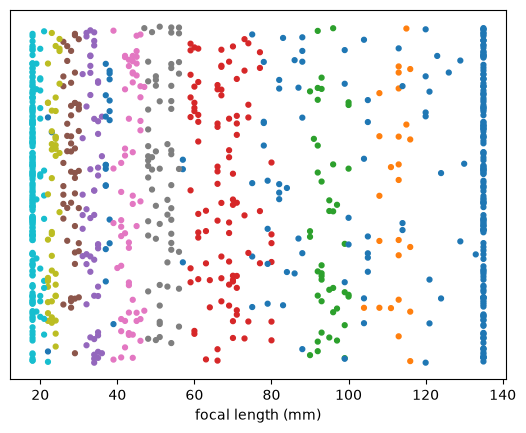

cluster 0: 121.0-135.0 mm, 165 photos
cluster 1: 104.0-116.0 mm, 25 photos
cluster 2: 90.0-100.0 mm, 44 photos
cluster 3: 59.0-80.0 mm, 95 photos
cluster 4: 31.0-36.0 mm, 56 photos
cluster 5: 26.0-30.0 mm, 52 photos
cluster 6: 39.0-47.0 mm, 62 photos
cluster 7: 47.0-56.0 mm, 63 photos
cluster 8: 22.0-25.0 mm, 46 photos
cluster 9: 19.0-22.0 mm, 26 photos
cluster 10: 18.0-18.0 mm, 164 photos
noise: 87 photos
Suggested eps = largest gap inside any cluster's range = 3.00 mm


In [2]:
from sklearn.cluster import HDBSCAN

MIN_CLUSTER_SIZE = 25
X = focal.reshape(-1, 1)
labels = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, copy=True).fit_predict(X)

clusters = sorted(set(labels) - {-1})
rng = np.random.default_rng(0)
plt.scatter(focal, rng.uniform(0, 1, len(focal)), c=labels, cmap="tab10", s=12)
plt.xlabel("focal length (mm)")
plt.yticks([])
plt.show()

for k in clusters:
    members = np.unique(focal[labels == k])
    print(f"cluster {k}: {members.min():.1f}-{members.max():.1f} mm, {np.sum(labels == k)} photos")
print(f"noise: {np.sum(labels == -1)} photos")

# Gaps between consecutive distinct values over ALL photos, so noise values are not skipped
values = np.unique(focal)
gaps = np.diff(values)
spans = [(focal[labels == k].min(), focal[labels == k].max()) for k in clusters]
inside = [gaps[i] for i in range(len(gaps)) if any(lo <= values[i] and values[i + 1] <= hi for lo, hi in spans)]
eps = max(inside, default=0.0)
print(f"Suggested eps = largest gap inside any cluster's range = {eps:.2f} mm")

## What to take away
Clusters that match real lens groups mean HDBSCAN found the structure without any `eps`. Many noise points mean `MIN_CLUSTER_SIZE` is too high for the spread of values. Compare the suggested `eps` with the results of notebooks 01–03.